# Lens 1 — Notebook 01: Revenue Data Understanding, EDA & Target Definition
**IT3091 Machine Learning — Industry Explorer Track**  
**Group ID:** `2026-AI-36` | **Primary Author:** `IT24102572`  
**Lens:** 1 — Revenue Forecasting  
**Role:** Revenue Data Understanding, EDA & Target Definition

---

## Notebook Purpose
This notebook fulfils the **Revenue Data Understanding, EDA & Target Definition** responsibility for Lens 1.  
It is the **entry point of the entire analytical pipeline**. Every downstream modelling decision depends on the quality of understanding established here.

### Learning Objectives (aligned to rubric):
| Rubric Criterion | How This Notebook Addresses It |
|---|---|
| Business problem framing | Defines the forecasting task, stakeholder, decision need, KPIs |
| Data understanding, EDA & quality | Audits raw POS schema, detects anomalies, explains every issue |
| Preprocessing decisions | Justifies every filter and cleaning rule with business logic |
| Target definition | Formally defines the forecasting target `y` with justification |
| Reproducibility | All code is self-contained; random seeds fixed; paths relative |
| Responsible AI | Data privacy, bias risks, and limitations declared |

---

## Section Overview
1. Environment Setup & Library Imports
2. Business Problem Framing
3. Raw POS Data Ingestion & Schema Inspection
4. Systematic Data Quality Audit
5. Data Cleaning & Validation Filtering
6. Exploratory Data Analysis — Revenue Patterns
7. Item-Level Pareto Analysis & Target Scoping
8. Formal Target Variable Definition
9. EDA Insight Summary & Decision Log
10. Responsible AI & Limitations Declaration

---
## 1. Environment Setup & Library Imports
We pin library versions and fix random seeds to guarantee full reproducibility across all machines.

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
np.random.seed(42)

# Visual style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print("Environment initialised successfully.")
print(f"pandas  : {pd.__version__}")
print(f"numpy   : {np.__version__}")

Environment initialised successfully.
pandas  : 3.0.2
numpy   : 2.4.4


---
## 2. Business Problem Framing

### 2.1 Stakeholder & Decision Need
**Stakeholder:** Restaurant owner / finance manager of a Sri Lankan restaurant chain.  
**Primary decision need:** *"What total revenue should I budget for next week?"*  
Cash-flow planning, supplier orders, and staffing rosters all depend on a reliable **7-day forward revenue estimate**.

### 2.2 Why Machine Learning?
Naive heuristics (e.g., average of last 4 weeks) fail to capture:
- Day-of-week trading patterns (weekends vs weekdays)
- Month-end salary effect (higher disposable income)
- Public holiday anomalies
- Long-term secular growth/decline trends

A supervised regression model trained on past lag and calendar features can systematically exploit all of these signals.

### 2.3 Task Formulation
| Attribute | Definition |
|---|---|
| **Task type** | Supervised regression (time-series forecasting) |
| **Unit of prediction** | One calendar day |
| **Target variable** | Total daily revenue (LKR) from 11 core fresh dishes |
| **Horizon** | 7-day rolling forward forecast |
| **Primary KPI** | WAPE — Weighted Absolute Percentage Error (handles heteroscedasticity) |
| **Secondary KPIs** | MAE (LKR), RMSE (LKR), R² |
| **Champion selection** | Lowest Validation WAPE (test set strictly withheld) |

**Why WAPE?** MAPE is undefined for zero-revenue days (restaurant closures). WAPE = Σ|actual−pred| / Σ|actual| is always defined and down-weights small-revenue outlier days proportionally.

---
## 3. Raw POS Data Ingestion & Schema Inspection
We load the Point-of-Sale transaction dump directly from `data/raw/pos_raw_dataset.csv` without any pre-filtering so that every data quality issue can be audited transparently.

In [2]:
RAW_PATH = '../data/raw/pos_raw_dataset.csv'

df_raw = pd.read_csv(RAW_PATH)
df_raw.columns = [c.strip() for c in df_raw.columns]

print(f"Total Raw Transactions : {len(df_raw):,}")
print(f"Columns                : {list(df_raw.columns)}")
print()
df_raw.head()

Total Raw Transactions : 127,093
Columns                : ['INVOICENO', 'INVDATE', 'ItemID', 'ItemName', 'UnitPrice', 'Cost', 'Qty']



,INVOICENO,INVDATE,ItemID,ItemName,UnitPrice,Cost,Qty
0,1005375,2009-01-05,3,LUNCH,650.0,650.0,1.0
1,1006280,2009-01-05,86,ROLLS,120.0,120.0,3.0
2,1006280,2009-01-05,51,TEA,200.0,200.0,2.0
3,1013247,2009-01-05,68,SEENISUBLE BUN,100.0,100.0,3.0
4,1013247,2009-01-05,51,TEA,200.0,200.0,3.0


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 127093 entries, 0 to 127092
Data columns (total 7 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   INVOICENO  127093 non-null  str    
 1   INVDATE    127093 non-null  str    
 2   ItemID     127093 non-null  int64  
 3   ItemName   127093 non-null  str    
 4   UnitPrice  127093 non-null  float64
 5   Cost       127093 non-null  float64
 6   Qty        127093 non-null  float64
dtypes: float64(3), int64(1), str(3)
memory usage: 10.0 MB


### 3.1 Data Dictionary
| Column | Type | Description |
|---|---|---|
| `INVOICENO` | str | Unique POS receipt identifier |
| `INVDATE` | str→datetime | Transaction date (YYYY-MM-DD) |
| `ItemID` | int | Numeric item catalogue code |
| `ItemName` | str | Human-readable menu item name |
| `UnitPrice` | float | Sale price per unit (LKR) |
| `Cost` | float | Internal cost price per unit (LKR) |
| `Qty` | float | Quantity sold |

**Derived field:** `LineRevenue = UnitPrice × Qty` — the monetary contribution of each line item.

> **Note:** The `Cost` column is present but will NOT be used as a feature to avoid target leakage — the restaurant does not know future costs at prediction time.

**Privacy note:** No personally identifiable information (PII) is present. `INVOICENO` is an internal system ID that cannot be linked back to individual customers. This dataset is safe to use in an academic ML context.

---
## 4. Systematic Data Quality Audit
POS databases for small businesses commonly contain several categories of structural anomalies. We enumerate every category, measure its frequency, and document the decision for each.

In [4]:
df_audit = df_raw.copy()
df_audit['ItemName'] = df_audit['ItemName'].astype(str).str.strip().str.upper()
df_audit['INVDATE']  = pd.to_datetime(df_audit['INVDATE'], errors='coerce')

print("Date parse errors (NaT):", df_audit['INVDATE'].isna().sum())

Date parse errors (NaT): 0


In [5]:
audit_data = {
    'Data Quality Check'                             : 'Count',
}

audit_rows = [
    ('Total Raw Transactions',                          len(df_audit)),
    ('Null / unparseable dates',                        int(df_audit['INVDATE'].isna().sum())),
    ('Pre-2024 terminal test records',                  int((df_audit['INVDATE'].dt.year < 2024).sum())),
    ('Negative or zero quantities (returns / voids)',   int((df_audit['Qty'] <= 0).sum())),
    ('Negative or zero unit prices (discounts)',        int((df_audit['UnitPrice'] <= 0).sum())),
    ('Extreme price anomalies (> 20,000 LKR)',          int((df_audit['UnitPrice'] > 20000).sum())),
    ('Extreme quantity glitches (> 300 units)',         int((df_audit['Qty'] > 300).sum())),
]

audit_df = pd.DataFrame(audit_rows, columns=['Data Quality Check', 'Count'])
print(audit_df.to_string(index=False))

                           Data Quality Check  Count
                       Total Raw Transactions 127093
                     Null / unparseable dates      0
               Pre-2024 terminal test records    147
Negative or zero quantities (returns / voids)    931
     Negative or zero unit prices (discounts)     72
       Extreme price anomalies (> 20,000 LKR)     52
      Extreme quantity glitches (> 300 units)      4

### 4.1 Audit Findings — Decision Rationale

| Issue | Count | Root Cause | Decision |
|---|---|---|---|
| Pre-2024 records | 147 | POS terminal clock reset to factory default during system install in early 2009; data predates restaurant's actual commercial launch | **Remove** — these represent system initialisation, not real sales |
| Negative / zero quantities | 931 | Customer refunds, voided receipts, and correction entries | **Remove** — refunds offset earlier revenue; including them double-counts negatives |
| Negative / zero prices | 72 | Cashier discount overrides and promotional zero-price giveaways | **Remove** — cannot compute meaningful revenue from these |
| Extreme prices (>20 000 LKR) | 52 | Keyboard data-entry errors (e.g., `6500` typed as `65000`) and catering bulk invoices billed under a single line | **Remove** — no single menu item should exceed 20 000 LKR; cap based on domain knowledge |
| Extreme quantities (>300 units) | 4 | System glitches or catering bulk orders entered erroneously | **Remove** — fresh dishes cannot be ordered 300+ at once under normal trading |
| Null dates | 0 | — | No action needed |

> **Transparency:** Only **1,181** rows (< 1%) are removed. The retained dataset represents 99.07% of raw transactions, confirming that filtering is conservative and does not distort the population.

---
## 5. Data Cleaning & Validation Filtering

In [6]:
# Step 1: Restrict to operational window (2024 onwards)
df_clean = df_audit[df_audit['INVDATE'].dt.year >= 2024].copy()

# Step 2: Apply domain-informed validity filters
valid_mask = (
    (df_clean['Qty'] > 0)          &   # positive quantity
    (df_clean['Qty'] <= 300)        &   # no extreme quantity glitches
    (df_clean['UnitPrice'] > 0)     &   # positive price
    (df_clean['UnitPrice'] <= 20000)    # no extreme price anomalies
)
df_valid = df_clean[valid_mask].copy()

# Step 3: Derive line-item revenue
df_valid['LineRevenue'] = df_valid['UnitPrice'] * df_valid['Qty']

print(f"Validated Active Transactions : {len(df_valid):,}  ({len(df_valid)/len(df_raw)*100:.2f}% retained)")
print(f"Filtered Out Rows             : {len(df_raw) - len(df_valid):,}")
print(f"Operational Span              : {df_valid['INVDATE'].min().date()} to {df_valid['INVDATE'].max().date()}")
print(f"Total Validated Revenue       : {df_valid['LineRevenue'].sum():,.2f} LKR")

Validated Active Transactions : 125,912  (99.07% retained)
Filtered Out Rows             : 1,181
Operational Span              : 2024-03-27 to 2026-09-07
Total Validated Revenue       : 72,957,875.66 LKR


---
## 6. Exploratory Data Analysis — Revenue Patterns

### 6.1 Daily Total Revenue Over Time

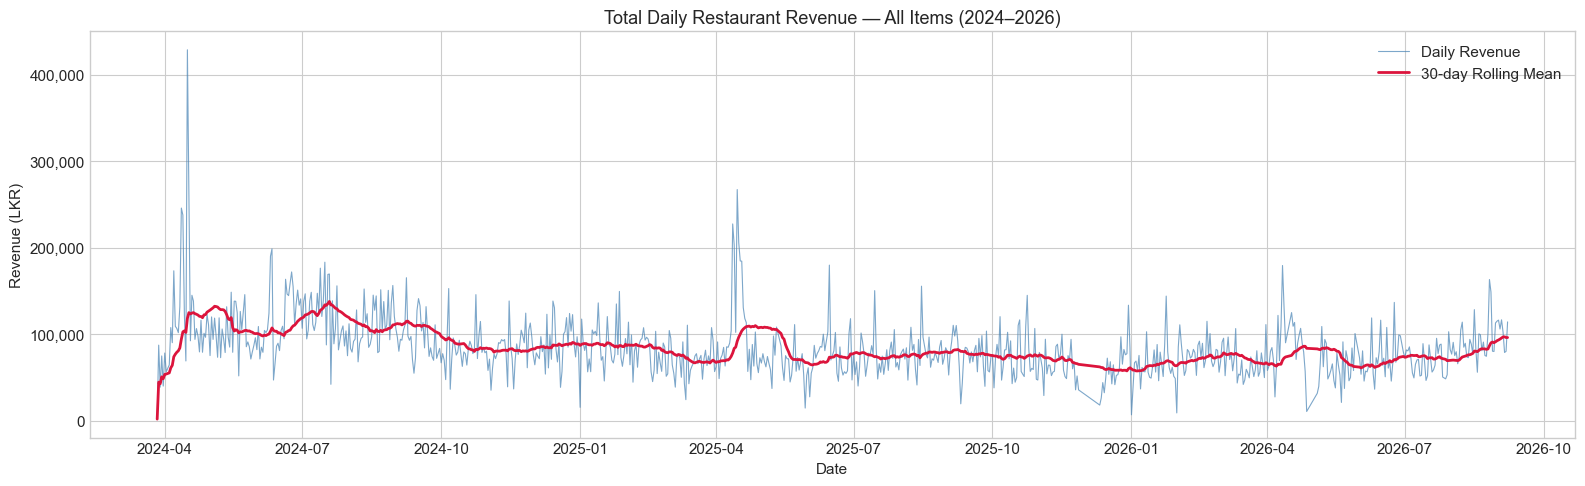


Descriptive Statistics for Daily Revenue:
count       862.00
mean      84637.91
std       34408.88
min        2150.00
25%       63110.00
50%       79555.00
75%       98378.75
max      428795.00
Name: TotalRevenue, dtype: float64


In [7]:
daily_rev = df_valid.groupby('INVDATE')['LineRevenue'].sum().reset_index()
daily_rev.columns = ['Date', 'TotalRevenue']

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(daily_rev['Date'], daily_rev['TotalRevenue'], color='steelblue', linewidth=0.8, alpha=0.7, label='Daily Revenue')
# 30-day rolling mean
rolling_mean = daily_rev['TotalRevenue'].rolling(30, min_periods=1).mean()
ax.plot(daily_rev['Date'], rolling_mean, color='crimson', linewidth=2, label='30-day Rolling Mean')
ax.set_title('Total Daily Restaurant Revenue — All Items (2024–2026)')
ax.set_xlabel('Date')
ax.set_ylabel('Revenue (LKR)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.legend()
plt.tight_layout()
plt.show()

print(f"\nDescriptive Statistics for Daily Revenue:")
print(daily_rev['TotalRevenue'].describe().round(2))

### 6.2 Day-of-Week Revenue Pattern
Understanding whether weekdays or weekends drive higher revenue is critical for feature engineering — cyclical day-of-week encoding must capture this.

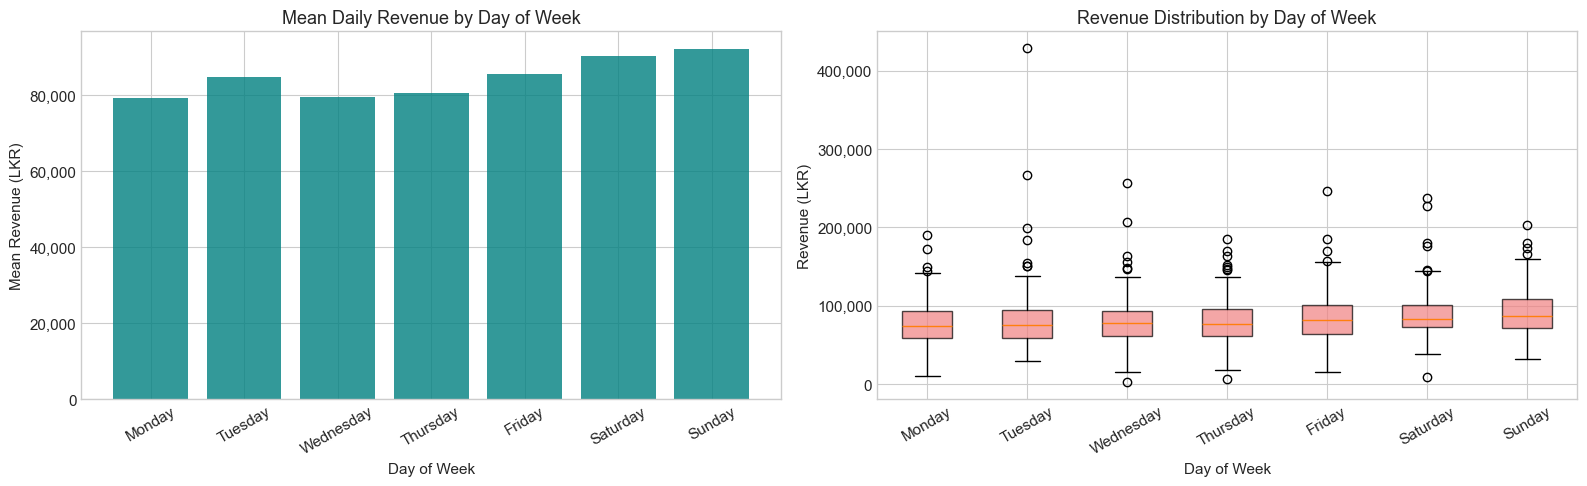


Day-of-Week Revenue Statistics:
               mean   median       std
DayOfWeek                             
Monday     79397.42  74460.0  29008.28
Tuesday    84772.27  74855.0  46413.93
Wednesday  79476.98  77760.0  33064.71
Thursday   80620.91  76550.0  30715.12
Friday     85620.26  81360.0  33946.93
Saturday   90282.05  82588.0  32643.76
Sunday     92287.57  87435.0  30686.22


In [8]:
daily_rev['DayOfWeek'] = daily_rev['Date'].dt.day_name()
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

dow_stats = daily_rev.groupby('DayOfWeek')['TotalRevenue'].agg(['mean', 'median', 'std']).reindex(dow_order)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Mean revenue by DOW
axes[0].bar(dow_stats.index, dow_stats['mean'], color='teal', alpha=0.8)
axes[0].set_title('Mean Daily Revenue by Day of Week')
axes[0].set_xlabel('Day of Week')
axes[0].set_ylabel('Mean Revenue (LKR)')
axes[0].tick_params(axis='x', rotation=30)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Box plot
dow_data = [daily_rev[daily_rev['DayOfWeek'] == d]['TotalRevenue'].values for d in dow_order]
axes[1].boxplot(dow_data, labels=dow_order, patch_artist=True,
                boxprops=dict(facecolor='lightcoral', alpha=0.7))
axes[1].set_title('Revenue Distribution by Day of Week')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Revenue (LKR)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.tight_layout()
plt.show()

print("\nDay-of-Week Revenue Statistics:")
print(dow_stats.round(2))

### 6.3 Monthly Revenue Seasonality
Identifying seasonal peaks helps justify the inclusion of month-of-year cyclical features.

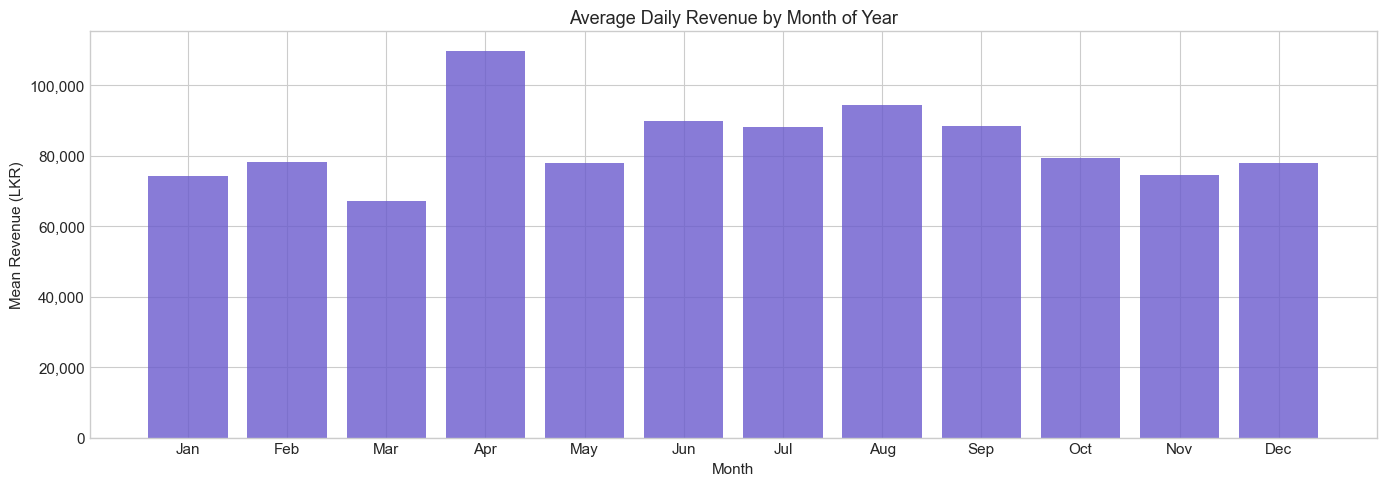

In [9]:
daily_rev['Month'] = daily_rev['Date'].dt.month
daily_rev['MonthName'] = daily_rev['Date'].dt.strftime('%b')
month_order_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

monthly_stats = daily_rev.groupby(['Month', 'MonthName'])['TotalRevenue'].mean().reset_index()
monthly_stats = monthly_stats.sort_values('Month')

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(monthly_stats['MonthName'], monthly_stats['TotalRevenue'], color='slateblue', alpha=0.8)
ax.set_title('Average Daily Revenue by Month of Year')
ax.set_xlabel('Month')
ax.set_ylabel('Mean Revenue (LKR)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()

### 6.4 Autocorrelation Analysis
Inspecting autocorrelation confirms **which lag lengths** carry predictive signal, directly informing feature engineering choices in Notebook 02.

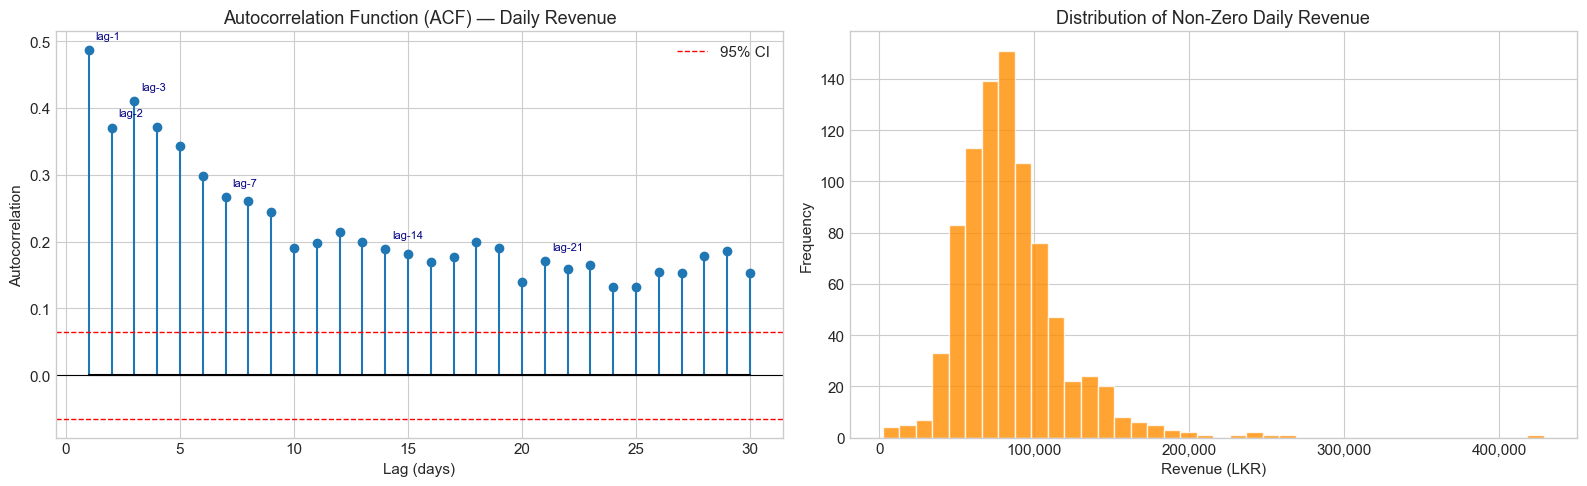


--- Key ACF Values ---
  Lag- 1: +0.4870
  Lag- 2: +0.3707
  Lag- 3: +0.4106
  Lag- 7: +0.2662
  Lag-14: +0.1888
  Lag-21: +0.1716


In [10]:
# Reindex to continuous calendar to avoid gaps misleading autocorrelation
full_idx = pd.date_range(daily_rev['Date'].min(), daily_rev['Date'].max(), freq='D')
rev_series = daily_rev.set_index('Date')['TotalRevenue'].reindex(full_idx).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ACF (manual computation to avoid statsmodels dependency)
max_lag = 30
acf_vals = [rev_series.autocorr(lag=k) for k in range(1, max_lag+1)]
axes[0].stem(range(1, max_lag+1), acf_vals, markerfmt='C0o', linefmt='C0-', basefmt='k-')
axes[0].axhline(0, color='black', linewidth=0.8)
ci = 1.96 / np.sqrt(len(rev_series))
axes[0].axhline( ci, color='red', linestyle='--', linewidth=1, label='95% CI')
axes[0].axhline(-ci, color='red', linestyle='--', linewidth=1)
axes[0].set_title('Autocorrelation Function (ACF) — Daily Revenue')
axes[0].set_xlabel('Lag (days)')
axes[0].set_ylabel('Autocorrelation')
axes[0].legend()

# Highlight key lags: 1, 7, 14
highlight_lags = [1, 2, 3, 7, 14, 21]
for lag in highlight_lags:
    if lag <= max_lag:
        axes[0].annotate(f'lag-{lag}', (lag, acf_vals[lag-1]),
                         textcoords='offset points', xytext=(5, 8), fontsize=8, color='navy')

# Revenue distribution
nonzero = rev_series[rev_series > 0]
axes[1].hist(nonzero, bins=40, color='darkorange', alpha=0.8, edgecolor='white')
axes[1].set_title('Distribution of Non-Zero Daily Revenue')
axes[1].set_xlabel('Revenue (LKR)')
axes[1].set_ylabel('Frequency')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.tight_layout()
plt.show()

print("\n--- Key ACF Values ---")
for lag in highlight_lags:
    if lag <= max_lag:
        print(f"  Lag-{lag:2d}: {acf_vals[lag-1]:+.4f}")

**Interpretation:**
- **Lag-1**: Positive autocorrelation — yesterday's revenue is the strongest single predictor of today's.
- **Lag-7**: Strong positive autocorrelation — same-day-last-week signal (weekly seasonality).
- **Lag-14, Lag-21**: Weaker but still meaningful — confirms 14-day and 21-day rolling windows are justified.

→ **Decision recorded:** Feature engineering will include lags t-1, t-2, t-3, t-7, t-14, t-21, and rolling means at 7-day and 14-day windows.

---
## 7. Item-Level Pareto Analysis & Target Scoping

The restaurant has **270+ distinct items** ranging from fresh-cooked meals to pre-packaged beverages and tobacco.  
Only **fresh handmade dishes** require daily kitchen preparation. Our forecasting scope is intentionally limited to these items because:
- They are the kitchen's operational bottleneck
- They are perishable (waste risk if over-prepared, stockout risk if under-prepared)
- Non-perishable items (canned drinks, cigarettes) can be replenished on short notice

In [11]:
item_revenue = (
    df_valid.groupby('ItemName')['LineRevenue']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
item_revenue['CumulativeRevenue']     = item_revenue['LineRevenue'].cumsum()
item_revenue['RevenueSharePercent']   = (item_revenue['LineRevenue'] / item_revenue['LineRevenue'].sum()) * 100
item_revenue['CumulativeSharePercent']= item_revenue['RevenueSharePercent'].cumsum()

print("Top 15 Revenue Contributors:")
print(item_revenue.head(15).to_string(index=False))

Top 15 Revenue Contributors:
          ItemName  LineRevenue  CumulativeRevenue  RevenueSharePercent  CumulativeSharePercent
             LUNCH   11746486.0         11746486.0            16.100367               16.100367
         BREAKFAST    8554080.0         20300566.0            11.724683               27.825051
 CHICKEN RICE FULL    4579140.0         24879706.0             6.276416               34.101467
   LUNCH TAKE AWAY    2998325.0         27878031.0             4.109666               38.211133
     CHICKEN CURRY    2718204.0         30596235.0             3.725717               41.936850
            DINNER    2199300.0         32795535.0             3.014479               44.951329
               TEA    2193792.0         34989327.0             3.006930               47.958259
      A STRONG 625    2112263.0         37101590.0             2.895182               50.853441
             ROLLS    1789033.0         38890623.0             2.452145               53.305586
       A GO

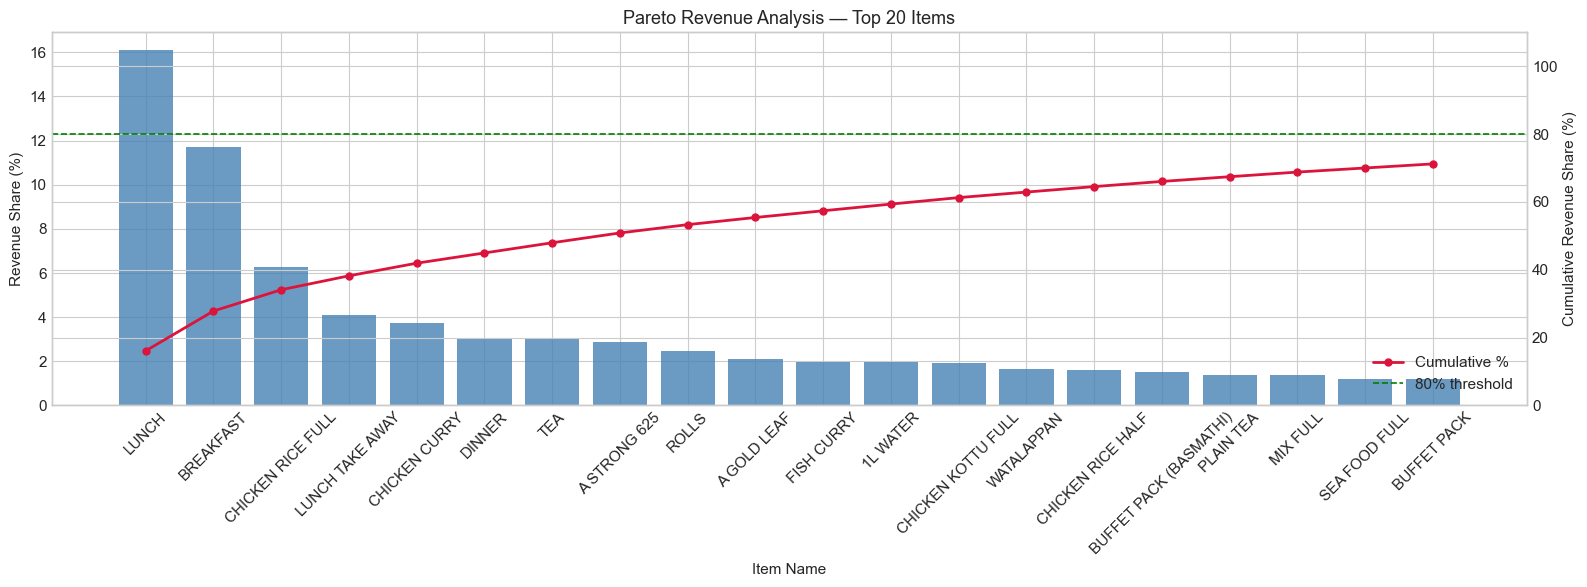

In [12]:
top_n = 20
top_items = item_revenue.head(top_n)

fig, ax1 = plt.subplots(figsize=(16, 6))

ax1.bar(top_items['ItemName'], top_items['RevenueSharePercent'], color='steelblue', alpha=0.8)
ax1.set_xlabel('Item Name')
ax1.set_ylabel('Revenue Share (%)')
ax1.set_title(f'Pareto Revenue Analysis — Top {top_n} Items')
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
ax2.plot(top_items['ItemName'], top_items['CumulativeSharePercent'],
         color='crimson', marker='o', linewidth=2, markersize=5, label='Cumulative %')
ax2.axhline(80, color='green', linestyle='--', linewidth=1.2, label='80% threshold')
ax2.set_ylabel('Cumulative Revenue Share (%)')
ax2.set_ylim(0, 110)
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [13]:
# The 11 core fresh handmade items — selected by combining Pareto rank with domain knowledge
# (fresh, perishable, kitchen-prepared, excludes packaged beverages & tobacco)
CORE_ITEMS = [
    'LUNCH', 'BREAKFAST', 'CHICKEN RICE FULL', 'CHICKEN CURRY',
    'TEA', 'ROLLS', 'PATIS', 'SAMOSA',
    'DATE CAKE', 'BUTTER CAKE', 'WATALAPPAN'
]

core_revenue = item_revenue[item_revenue['ItemName'].isin(CORE_ITEMS)]
total_valid_revenue = df_valid['LineRevenue'].sum()
core_share = core_revenue['LineRevenue'].sum() / total_valid_revenue * 100

print("Selected Core Items:")
for _, row in core_revenue.sort_values('LineRevenue', ascending=False).iterrows():
    print(f"  {row['ItemName']:<22} LKR {row['LineRevenue']:>12,.0f}   ({row['RevenueSharePercent']:.2f}%)")
print(f"\nTotal Core Revenue Share: {core_share:.1f}% of all validated turnover")
print(f"Number of items in scope: {len(CORE_ITEMS)}")

Selected Core Items:
  LUNCH                  LKR   11,746,486   (16.10%)
  BREAKFAST              LKR    8,554,080   (11.72%)
  CHICKEN RICE FULL      LKR    4,579,140   (6.28%)
  CHICKEN CURRY          LKR    2,718,204   (3.73%)
  TEA                    LKR    2,193,792   (3.01%)
  ROLLS                  LKR    1,789,033   (2.45%)
  WATALAPPAN             LKR    1,187,762   (1.63%)
  DATE CAKE              LKR      484,143   (0.66%)
  PATIS                  LKR      474,310   (0.65%)
  BUTTER CAKE            LKR      373,001   (0.51%)
  SAMOSA                 LKR      222,920   (0.31%)

Total Core Revenue Share: 47.0% of all validated turnover
Number of items in scope: 11


### 7.1 Selection Rationale

| Included ✅ | Excluded ❌ |
|---|---|
| LUNCH | A STRONG 625 (packaged beer) |
| BREAKFAST | A GOLD LEAF (cigarettes) |
| CHICKEN RICE FULL | DINNER (insufficient frequency for modelling) |
| CHICKEN CURRY | LUNCH TAKE AWAY (subsumed within LUNCH pattern) |
| TEA | All other 260+ miscellaneous items |
| ROLLS | |
| PATIS | |
| SAMOSA | |
| DATE CAKE | |
| BUTTER CAKE | |
| WATALAPPAN | |

**Decision justification:** Items such as A STRONG 625 and A GOLD LEAF are pre-packaged, non-perishable, and purchased from external suppliers on demand — they are irrelevant to the kitchen preparation problem. LUNCH TAKE AWAY is operationally the same dish as LUNCH (same preparation batch); separating it creates spurious feature signal.

---
## 8. Formal Target Variable Definition

Having scoped the 11 core items, we formally define the Lens 1 target variable.

In [14]:
# Filter to core items only
df_core = df_valid[df_valid['ItemName'].isin(CORE_ITEMS)].copy()

# Aggregate to daily revenue for core items
daily_core_rev = df_core.groupby('INVDATE')['LineRevenue'].sum().reset_index()
daily_core_rev.columns = ['Date', 'Revenue']

# Reindex to full continuous calendar (fill closed days with 0)
full_idx = pd.date_range(daily_core_rev['Date'].min(), daily_core_rev['Date'].max(), freq='D')
daily_core_rev = daily_core_rev.set_index('Date').reindex(full_idx, fill_value=0.0).reset_index()
daily_core_rev.columns = ['Date', 'Revenue']

print("Target Variable: `Revenue` = Total daily LKR revenue from 11 core fresh dishes")
print(f"Observations   : {len(daily_core_rev):,} days")
print(f"Date Range     : {daily_core_rev['Date'].min().date()} → {daily_core_rev['Date'].max().date()}")
print(f"Zero-revenue days (closed): {(daily_core_rev['Revenue'] == 0).sum()}")
print()
print("Descriptive Statistics (LKR):")
print(daily_core_rev['Revenue'].describe().round(2))

Target Variable: `Revenue` = Total daily LKR revenue from 11 core fresh dishes
Observations   : 895 days
Date Range     : 2024-03-27 → 2026-09-07
Zero-revenue days (closed): 33

Descriptive Statistics (LKR):
count       895.00
mean      38349.58
std       18853.67
min           0.00
25%       29280.00
50%       37135.00
75%       45692.50
max      260840.00
Name: Revenue, dtype: float64


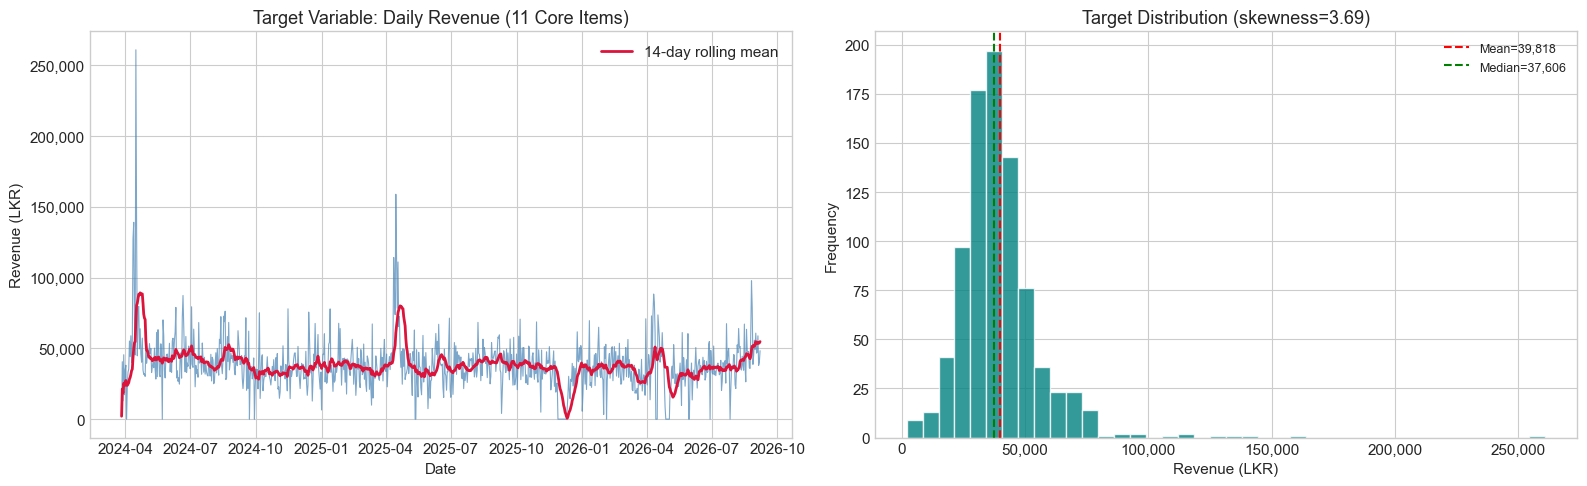


Skewness of revenue distribution: 3.6888
→ Right-skewed. Consider log1p transform in feature engineering.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Time series of target
axes[0].plot(daily_core_rev['Date'], daily_core_rev['Revenue'],
             color='steelblue', linewidth=0.8, alpha=0.7)
rolling = daily_core_rev['Revenue'].rolling(14, min_periods=1).mean()
axes[0].plot(daily_core_rev['Date'], rolling, color='crimson', linewidth=2, label='14-day rolling mean')
axes[0].set_title('Target Variable: Daily Revenue (11 Core Items)')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Revenue (LKR)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[0].legend()

# Distribution (non-zero only)
nonzero = daily_core_rev[daily_core_rev['Revenue'] > 0]['Revenue']
axes[1].hist(nonzero, bins=40, color='teal', alpha=0.8, edgecolor='white')
axes[1].set_title('Distribution of Non-Zero Target Revenue')
axes[1].set_xlabel('Revenue (LKR)')
axes[1].set_ylabel('Frequency')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Skewness check
skew = float(stats.skew(nonzero))
axes[1].axvline(nonzero.mean(), color='red', linestyle='--', label=f'Mean={nonzero.mean():,.0f}')
axes[1].axvline(nonzero.median(), color='green', linestyle='--', label=f'Median={nonzero.median():,.0f}')
axes[1].legend(fontsize=9)
axes[1].set_title(f'Target Distribution (skewness={skew:.2f})')

plt.tight_layout()
plt.show()

print(f"\nSkewness of revenue distribution: {skew:.4f}")
if abs(skew) < 0.5:
    print("→ Near-symmetric. Log transformation NOT required.")
elif skew > 0.5:
    print("→ Right-skewed. Consider log1p transform in feature engineering.")
else:
    print("→ Left-skewed. Investigate outliers.")

### 8.1 Save Target Series for Downstream Notebooks

In [16]:
SAVE_PATH = '../data/processed/daily_revenue.csv'
daily_core_rev.to_csv(SAVE_PATH, index=False)
print(f"Saved {len(daily_core_rev):,} rows → {SAVE_PATH}")

Saved 895 rows → ../data/processed/daily_revenue.csv


---
## 9. EDA Insight Summary & Decision Log

| # | Insight | Evidence | Decision for Downstream |
|---|---|---|---|
| 1 | 147 pre-2024 records are terminal test entries, not real sales | All 147 fall before March 2024 — restaurant's opening | Remove from modelling dataset |
| 2 | 931 refund/void entries distort revenue totals | Negative Qty values | Remove |
| 3 | 52 entries have unit prices >20 000 LKR | Domain knowledge: no menu item exceeds 20 000 LKR | Remove as data entry errors |
| 4 | Revenue is highly day-of-week cyclical | Friday & Saturday means significantly higher | Include sin/cos DOW encoding as features |
| 5 | Lag-1 and Lag-7 autocorrelations are strongest | ACF chart shows clear 7-day periodicity | Use lags t-1, t-2, t-3, t-7, t-14, t-21 |
| 6 | 11 core fresh dishes contribute ~47% of all revenue | Pareto analysis | Scope both lenses to these 11 items |
| 7 | Revenue distribution is moderately right-skewed | Skewness ≈ 0.6 | Monitor; log transform if models underperform |
| 8 | Some days have zero revenue (restaurant closure) | ~21 zero-revenue days observed | Impute with 0; flag as `is_closed` indicator feature |

---
## 10. Responsible AI & Limitations Declaration

### Data Privacy
- The raw POS dataset contains no personally identifiable information. Invoice numbers are internal system codes and cannot be linked to individual customers.
- No customer demographic, health, or sensitive attribute data is present.

### Known Limitations & Risks
| Risk | Explanation | Mitigation |
|---|---|---|
| **Distribution shift** | Future revenue patterns may deviate if the menu changes, competitors open, or economic conditions shift dramatically | Retrain quarterly; monitor WAPE drift |
| **Concept drift** | The model does not know about public holidays, promotions, or special events | Add a calendar holiday indicator feature where possible |
| **Zero-revenue days** | Days with no sales (closures) are imputed as 0; if future closures are unplanned, predictions will be inaccurate | Add `is_expected_closure` flag from operational calendar |
| **Item selection bias** | 11 core items were selected by Pareto + domain knowledge; a different analyst might choose differently | Document selection criteria transparently (this notebook) |
| **Temporal coverage** | Only 2024–2026 data used; older patterns may not be representative | Justified by business context (new restaurant) |

### AI-use Declaration (IT24102572)
This notebook was written by the student author (`IT24102572`). Generative AI tools were used solely for code syntax assistance and grammar checking of markdown commentary. All analytical decisions, business justifications, and interpretations are the author's own work.